# Chapter 4 Empirical Analysis
This notebook is the **revised and fully aligned** empirical implementation for **Chapter 4**, reflecting the updated methodology in **Chapter 3** of the revised proposal (return construction, realised volatility proxy, alternative innovation distributions, rolling forecasting design, QLIKE evaluation, SPA, and MCS).  

**Models implemented**
1. **GARCH(1,1)** with Gaussian and Student-t innovations  
2. **IGARCH(1,1)** (constraint \(\alpha+\beta=1\)) estimated by constrained MLE  
3. **Sentiment-augmented GARCH-X**: \(\sigma_t^2 = \omega + \alpha\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2 + \gamma S_{t-1}\)  
4. **Random Forest** variance forecasts using lagged returns, volume, rolling volatility, and sentiment lags  
5. **Hybrid RF** using walk-forward GARCH conditional volatility as an additional feature (no look-ahead)

**Forecasting design**
- **One-step-ahead** variance forecasts
- **Rolling-window** walk-forward estimation (default rolling window length configurable)

**Evaluation**
- Primary: **QLIKE** (Patton-style) loss with realised volatility proxy \(RV_t=r_t^2\)
- Benchmark comparisons via **loss differentials**
- Multiple-model inference via **block bootstrap SPA** and **Model Confidence Set (MCS)**

> **Reproducibility note:** This notebook is written to be run end-to-end. If you change the dataset path, update `MERGED_FILE` in the configuration cell.


In [1]:
# =========================
# 0. Imports & configuration
# =========================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import re

from pathlib import Path

import matplotlib.pyplot as plt

from arch import arch_model

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler

from scipy.optimize import minimize
from scipy.stats import ttest_rel

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

# -------------------------
# Project paths
# -------------------------
DATA_DIR = Path("../Data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

MERGED_FILE = DATA_DIR / "final_data.csv"   # Date, Open, Close, Volume, Search_Interest (or Trends)

OUT_DIR = Path("./outputs")
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR = OUT_DIR / "figures"
IGARCH_DIR = Path("./igarch")  # R-generated IGARCH CSV files

OUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------
# Helper functions (tables & figures)
# -------------------------
def sanitize_column_name(name: str) -> str:
    """Replace underscores with spaces in column names for LaTeX readability."""
    return name.replace("_", " ")

def sanitize_dataframe_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Sanitize all column names in a DataFrame for LaTeX output."""
    df = df.copy()
    df.columns = [sanitize_column_name(str(col)) for col in df.columns]
    return df

def auto_label_from_filename(filename: str, kind: str) -> str:
    """Generate a short LaTeX label from a filename (e.g., tab:adf, fig:acf_returns)."""
    stem = Path(filename).stem.lower()
    stem = re.sub(r"^(table|fig)_[0-9]+_[0-9]+_", "", stem)
    stem = re.sub(r"^(table|fig)_", "", stem)

    keyword_map = [
        ("correlation_matrix_spearman", "correlation_spearman"),
        ("correlation_matrix", "correlation"),
        ("forecast_loss_ranking", "forecast_loss_ranking"),
        ("forecast_loss_summary", "forecast_loss_summary"),
        ("residual_diagnostics", "residual_diagnostics"),
        ("rf_feature_importance", "rf_feature_importance"),
        ("model_specifications", "model_spec"),
        ("jarque_bera", "jarque_bera"),
        ("ljung_box", "ljung_box"),
        ("acf_squared_returns", "acf_squared_returns"),
        ("acf_returns", "acf_returns"),
        ("arch_lm", "arch_lm"),
        ("quantiles", "quantiles"),
        ("descriptives", "descriptives"),
        ("garchx", "garchx"),
        ("igarch", "igarch"),
        ("garch", "garch"),
        ("kpss", "kpss"),
        ("adf", "adf"),
    ]
    for key, short in keyword_map:
        if key in stem:
            return f"{kind}:{short}"

    slug = re.sub(r"[^a-z0-9]+", "_", stem).strip("_")
    if not slug:
        slug = "table" if kind == "tab" else "figure"
    return f"{kind}:{slug}"

def save_table_latex_hierarchical(
    df: pd.DataFrame,
    filename: str,
    float_fmt: str = "%.4f",
    caption: str | None = None,
    label: str | None = None,
    index: bool = True,
    escape: bool = False,
    multicolumn_format: str = "c",
    position: str = "htbp",
    auto_label: bool = True,
) -> None:
    """Save DataFrame as LaTeX table with MultiIndex support and optional caption/label."""
    path = TABLE_DIR / filename

    if label is None and auto_label:
        label = auto_label_from_filename(filename, "tab")

    df_clean = df.copy()

    # Sanitize column names (including MultiIndex columns)
    if isinstance(df_clean.columns, pd.MultiIndex):
        new_cols = []
        for tup in df_clean.columns:
            new_cols.append(tuple(sanitize_column_name(str(x)) for x in tup))
        new_names = [
            sanitize_column_name(str(n)) if n is not None else None
            for n in df_clean.columns.names
        ]
        df_clean.columns = pd.MultiIndex.from_tuples(new_cols, names=new_names)
    else:
        df_clean = sanitize_dataframe_columns(df_clean)

    # Sanitize index names (not values)
    if isinstance(df_clean.index, pd.MultiIndex):
        new_index_names = [
            sanitize_column_name(str(n)) if n is not None else None
            for n in df_clean.index.names
        ]
        df_clean.index = df_clean.index.set_names(new_index_names)
    elif df_clean.index.name is not None:
        df_clean.index.name = sanitize_column_name(str(df_clean.index.name))

    tex = df_clean.to_latex(
        float_format=lambda x: float_fmt % x,
        index=index,
        escape=escape,
        multirow=True,
        multicolumn=True,
        multicolumn_format=multicolumn_format,
    )

    if caption or label:
        parts = [f"\\begin{{table}}[{position}]", "\\centering", tex.rstrip()]
        if caption:
            parts.append(f"\\caption{{{caption}}}")
        if label:
            parts.append(f"\\label{{{label}}}")
        parts.append("\\end{table}")
        tex = "\n".join(parts) + "\n"

    path.write_text(tex)
    print(f"Saved LaTeX table → {path}")
    if label:
        print(f"  Label for reference: {label}")
def save_figure_png(
    filename: str,
    dpi: int = 300,
    label: str | None = None,
    auto_label: bool = True,
) -> str | None:
    path = FIG_DIR / filename
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"Saved figure → {path}")

    if label is None and auto_label:
        label = auto_label_from_filename(filename, "fig")
    if label:
        print(f"  Label for reference: {label}")
    return label

# -------------------------
# Core settings (edit safely)
# -------------------------
TEST_SIZE = 0.20                 # out-of-sample fraction
ROLLING_WINDOW = 750             # rolling estimation window length (~3 years of daily data)
INNOVATIONS = ["normal", "t"]    # GARCH innovations
RANDOM_STATE = 42

# Bootstrap settings for SPA / MCS
BOOTSTRAP_B = 1000
BLOCK_LEN = 10
MCS_ALPHA = 0.10

## 4.0: Load data and harmonize columns

Expected columns (minimum):
- `Date`
- `Close`
- `Volume`
- `Search_Interest` (or `Trends` which will be renamed)

The sample is then sorted, indexed by Date, and checked for missing values.


In [2]:
from pathlib import Path
import pandas as pd

def load_data(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)

    try:
        df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
    except Exception:
        df["Date"] = pd.to_datetime(df["Date"])

    df = df.set_index("Date").sort_index()

    if "Trends" in df.columns and "Search_Interest" not in df.columns:
        df = df.rename(columns={"Trends": "Search_Interest"})

    required = ["Close", "Volume"]
    for c in required:
        if c not in df.columns:
            raise ValueError(f"Missing required column: {c}")

    if "Search_Interest" not in df.columns:
        raise ValueError("Missing sentiment column.")

    return df


# THIS is what makes the head appear
df_raw = load_data(MERGED_FILE)
df_raw.head()


,Open,Close,Volume,Search_Interest
Date,,,,
2017-01-01,963.658020,998.325012,147775008.0,14
2017-01-02,998.617004,1021.750000,222184992.0,27
2017-01-03,1021.599976,1043.839966,185168000.0,25
2017-01-04,1044.400024,1154.729980,344945984.0,28
2017-01-05,1156.729980,1013.380005,510199008.0,35


### 4.1.0 Transformations

In [3]:
import numpy as np

def prepare_returns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Log returns (percent)
    df["log_return"] = np.log(df["Close"] / df["Close"].shift(1)) * 100

    # Volatility proxies
    df["sq_return"] = df["log_return"] ** 2
    df["abs_return"] = df["log_return"].abs()

    # Log volume (useful later for RF)
    df["log_volume"] = np.log(df["Volume"])

    # Drop first observation
    df = df.dropna()

    return df

df = prepare_returns(df_raw)
df.head()

,Open,Close,Volume,Search_Interest,log_return,sq_return,abs_return,log_volume
Date,,,,,,,,
2017-01-02,998.617004,1021.750000,222184992.0,27,2.319324,5.379262,2.319324,19.219021
2017-01-03,1021.599976,1043.839966,185168000.0,25,2.138934,4.575041,2.138934,19.036774
2017-01-04,1044.400024,1154.729980,344945984.0,28,10.096034,101.929912,10.096034,19.658898
2017-01-05,1156.729980,1013.380005,510199008.0,35,-13.057525,170.498959,13.057525,20.050311
2017-01-06,1014.239990,902.200989,351876000.0,29,-11.620924,135.045878,11.620924,19.678789


### 4.1.1: Core distributional statistics
We calculate the mean, standard deviation, minimum and maximum values, skewness, and Kurtosis

In [4]:
import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis

def core_descriptive_stats(series: pd.Series) -> pd.Series:
    return pd.Series({
        "Mean": series.mean(),
        "Std. Dev.": series.std(),
        "Min": series.min(),
        "Max": series.max(),
        "Skewness": skew(series, nan_policy="omit"),
        "Kurtosis": kurtosis(series, fisher=True, nan_policy="omit")
    })

desc_411 = pd.concat({
    "Returns": core_descriptive_stats(df["log_return"]),
    "Squared Returns": core_descriptive_stats(df["sq_return"]),
    "Sentiment": core_descriptive_stats(df["Search_Interest"])
}, axis=1)

save_table_latex_hierarchical(
    desc_411,
    "table_4_1_core_descriptives.tex",
    label="tab:descriptive_stats"
)

desc_411

Saved LaTeX table → outputs/tables/table_4_1_core_descriptives.tex
  Label for reference: tab:descriptive_stats


,Returns,Squared Returns,Sentiment
Mean,0.151482,13.599002,37.574157
Std. Dev.,3.685156,49.966437,18.419950
Min,-46.473018,0.000000,5.000000
Max,22.511895,2159.741359,100.000000
Skewness,-0.659419,26.910157,0.657471
Kurtosis,11.643323,1091.696906,0.315633


### 4.1.2 Quantiles and tail behaviour

In [5]:
# -------------------------
# 4.1.2 Quantiles and Tail Behaviour
# -------------------------
quantiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]

quantile_412 = pd.DataFrame({
    "Returns": df["log_return"].quantile(quantiles),
    "Squared Returns": df["sq_return"].quantile(quantiles),
    "Sentiment": df["Search_Interest"].quantile(quantiles)
})

# Nice index labels
quantile_412.index = [f"{int(q*100)}%" if q in [0.01,0.05,0.50,0.95,0.99] else f"{int(q*100)}%" for q in quantiles]

# Save to LaTeX
save_table_latex_hierarchical(quantile_412, "table_4_2_quantiles_tail_behaviour.tex", float_fmt="%.4f")

quantile_412  # display in notebook


Saved LaTeX table → outputs/tables/table_4_2_quantiles_tail_behaviour.tex
  Label for reference: tab:quantiles


,Returns,Squared Returns,Sentiment
1%,-10.602982,0.000669,7.41
5%,-5.873204,0.012844,12.00
25%,-1.357782,0.387232,22.00
50%,0.127514,2.359679,36.00
75%,1.733894,10.719347,49.00
95%,5.844212,59.499894,70.00
99%,10.155747,146.332575,93.00


### 4.1.3 Dependence and persistence diagnostics

Saved figure → outputs/figures/fig_4_1_3_acf_returns.png
  Label for reference: fig:acf_returns


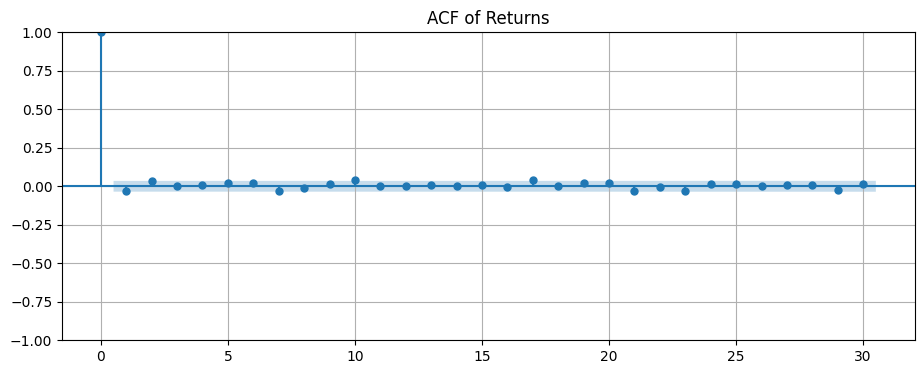

Saved figure → outputs/figures/fig_4_1_3_acf_squared_returns.png
  Label for reference: fig:acf_squared_returns


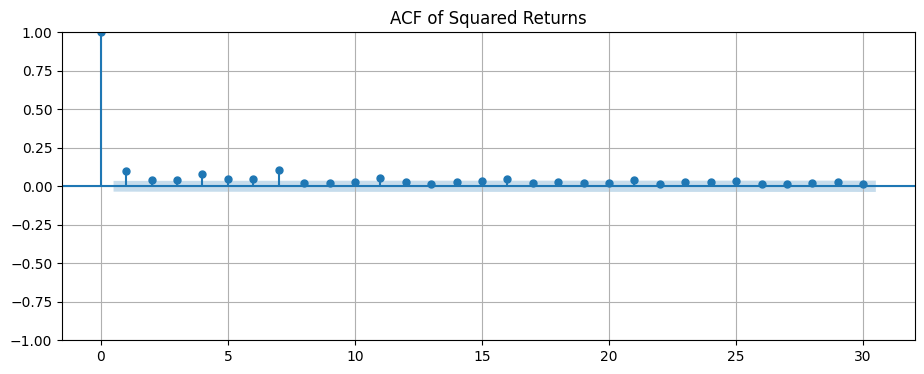

Saved LaTeX table → outputs/tables/table_4_3_ljung_box_tests.tex
  Label for reference: tab:ljung_box


Returns           Squared Returns              
      lb_stat lb_pvalue         lb_stat     lb_pvalue
10  19.498774  0.034366      119.247679  7.190884e-21
20  28.654020  0.094799      150.687852  4.640968e-22

In [6]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

LAGS = 30

# -------------------------
# ACF of returns
# -------------------------
fig = plot_acf(df["log_return"], lags=LAGS)
plt.title("ACF of Returns")
save_figure_png("fig_4_1_3_acf_returns.png")
plt.show()

# -------------------------
# ACF of squared returns (volatility clustering)
# -------------------------
fig = plot_acf(df["sq_return"], lags=LAGS)
plt.title("ACF of Squared Returns")
save_figure_png("fig_4_1_3_acf_squared_returns.png")
plt.show()

from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung–Box tests for returns
lb_returns = acorr_ljungbox(
    df["log_return"], lags=[10, 20], return_df=True
)

# Ljung–Box tests for squared returns
lb_sq_returns = acorr_ljungbox(
    df["sq_return"], lags=[10, 20], return_df=True
)

# Combine into a single table
lb_413 = pd.concat(
    {
        "Returns": lb_returns[["lb_stat", "lb_pvalue"]],
        "Squared Returns": lb_sq_returns[["lb_stat", "lb_pvalue"]],
    },
    axis=1
)

# Save then display
save_table_latex_hierarchical(lb_413, "table_4_3_ljung_box_tests.tex", float_fmt="%.4f")
lb_413


### 4.1.4 Normality and distributional tests
Jarque-Bera test
- statistic
- p-value

In [7]:
from scipy.stats import jarque_bera

def jb_test(series: pd.Series) -> pd.Series:
    jb_stat, jb_pvalue = jarque_bera(series.dropna())
    return pd.Series({
        "JB Statistic": jb_stat,
        "p-value": jb_pvalue
    })

jb_414 = pd.concat(
    {
        "Returns": jb_test(df["log_return"]),
        "Squared Returns": jb_test(df["sq_return"]),
        "Sentiment": jb_test(df["Search_Interest"])
    },
    axis=1
)

# Save then display
save_table_latex_hierarchical(jb_414, "table_4_4_jarque_bera_tests.tex", float_fmt="%.4f")
jb_414


Saved LaTeX table → outputs/tables/table_4_4_jarque_bera_tests.tex
  Label for reference: tab:jarque_bera


,Returns,Squared Returns,Sentiment
JB Statistic,17975.682564,1.564060e+08,2.394072e+02
p-value,0.000000,0.000000e+00,1.031313e-52


### 4.1.5: Stationarity diagnostics
ADF tests
KPSS tests for robustness

In [8]:
from statsmodels.tsa.stattools import adfuller

def adf_test(series: pd.Series, maxlag: int = None) -> pd.Series:
    result = adfuller(series.dropna(), maxlag=maxlag, autolag="AIC")
    return pd.Series({
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Used Lags": result[2],
        "Observations": result[3]
    })

adf_415 = pd.concat(
    {
        "Returns": adf_test(df["log_return"]),
        "Squared Returns": adf_test(df["sq_return"]),
        "Sentiment": adf_test(df["Search_Interest"])
    },
    axis=1
)

# Save then display
save_table_latex_hierarchical(adf_415, "table_4_5_adf_stationarity_tests.tex", float_fmt="%.4f")
adf_415

from statsmodels.tsa.stattools import kpss

def kpss_test(series: pd.Series, regression: str = "c") -> pd.Series:
    stat, p_value, lags, _ = kpss(series.dropna(), regression=regression, nlags="auto")
    return pd.Series({
        "KPSS Statistic": stat,
        "p-value": p_value,
        "Used Lags": lags
    })

kpss_415 = pd.concat(
    {
        "Returns": kpss_test(df["log_return"]),
        "Squared Returns": kpss_test(df["sq_return"]),
        "Sentiment": kpss_test(df["Search_Interest"])
    },
    axis=1
)

# Save then display
save_table_latex_hierarchical(kpss_415, "table_4_5_kpss_stationarity_tests.tex", float_fmt="%.4f")
kpss_415


Saved LaTeX table → outputs/tables/table_4_5_adf_stationarity_tests.tex
  Label for reference: tab:adf
Saved LaTeX table → outputs/tables/table_4_5_kpss_stationarity_tests.tex
  Label for reference: tab:kpss


/var/folders/g9/rt7qc_417g5g_s_ns1c13s_r0000gn/T/ipykernel_9812/3541211885.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, p_value, lags, _ = kpss(series.dropna(), regression=regression, nlags="auto")
/var/folders/g9/rt7qc_417g5g_s_ns1c13s_r0000gn/T/ipykernel_9812/3541211885.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, p_value, lags, _ = kpss(series.dropna(), regression=regression, nlags="auto")
/var/folders/g9/rt7qc_417g5g_s_ns1c13s_r0000gn/T/ipykernel_9812/3541211885.py:28: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, p_value, lags, _ = kpss(series.dropna(), regression=regression, nlags="au

,Returns,Squared Returns,Sentiment
KPSS Statistic,0.142971,2.151845,1.282713
p-value,0.100000,0.010000,0.010000
Used Lags,8.000000,17.000000,31.000000


### 4.1.6 Correlation analysis
#### a: Correlation matrix

In [9]:
# -------------------------
# 4.1.6 Correlation Analysis
# -------------------------
corr_vars = [
    "log_return",
    "sq_return",
    "abs_return",
    "Search_Interest"
]

corr_416 = df[corr_vars].corr()

# Save then display
save_table_latex_hierarchical(corr_416, "table_4_6_correlation_matrix.tex", float_fmt="%.4f")
corr_416


Saved LaTeX table → outputs/tables/table_4_6_correlation_matrix.tex
  Label for reference: tab:correlation


,log_return,sq_return,abs_return,Search_Interest
log_return,1.000000,-0.156851,-0.032599,-0.021196
sq_return,-0.156851,1.000000,0.769021,0.110383
abs_return,-0.032599,0.769021,1.000000,0.151439
Search_Interest,-0.021196,0.110383,0.151439,1.000000


#### b: Rank correlations

In [10]:
corr_416_spearman = df[corr_vars].corr(method="spearman")

save_table_latex_hierarchical(
    corr_416_spearman,
    "table_4_6_correlation_matrix_spearman.tex",
    float_fmt="%.4f"
)

corr_416_spearman


Saved LaTeX table → outputs/tables/table_4_6_correlation_matrix_spearman.tex
  Label for reference: tab:correlation_spearman


,log_return,sq_return,abs_return,Search_Interest
log_return,1.000000,0.075408,0.075408,-0.027488
sq_return,0.075408,1.000000,1.000000,0.094341
abs_return,0.075408,1.000000,1.000000,0.094341
Search_Interest,-0.027488,0.094341,0.094341,1.000000


## 4.2 Model estimation results
### 4.2.0 Estimation and training setup

In [11]:
# -------------------------
# 4.2.0 Estimation sample definition
# -------------------------
T = len(df)
split_idx = int((1 - TEST_SIZE) * T)

df_est = df.iloc[:split_idx].copy()
df_oos = df.iloc[split_idx:].copy()

print(f"Total observations:      {T}")
print(f"In-sample (estimation):  {len(df_est)}")
print(f"Out-of-sample:           {len(df_oos)}")
print(f"In-sample start/end:     {df_est.index.min().date()} → {df_est.index.max().date()}")
print(f"Out-of-sample start/end: {df_oos.index.min().date()} → {df_oos.index.max().date()}")

# Quick sanity check
df_est.head()


Total observations:      3142
In-sample (estimation):  2513
Out-of-sample:           629
In-sample start/end:     2017-01-02 → 2023-11-19
Out-of-sample start/end: 2023-11-20 → 2025-08-09


,Open,Close,Volume,Search_Interest,log_return,sq_return,abs_return,log_volume
Date,,,,,,,,
2017-01-02,998.617004,1021.750000,222184992.0,27,2.319324,5.379262,2.319324,19.219021
2017-01-03,1021.599976,1043.839966,185168000.0,25,2.138934,4.575041,2.138934,19.036774
2017-01-04,1044.400024,1154.729980,344945984.0,28,10.096034,101.929912,10.096034,19.658898
2017-01-05,1156.729980,1013.380005,510199008.0,35,-13.057525,170.498959,13.057525,20.050311
2017-01-06,1014.239990,902.200989,351876000.0,29,-11.620924,135.045878,11.620924,19.678789


### 4.2.1 Model specification and estimation setup

In [12]:
# -------------------------
# 4.2.1 Model specifications & estimation setup
# -------------------------

# Core choices (align these with Chapter 3)
RETURN_COL = "log_return"
SENT_COL = "Search_Interest"

# Volatility proxy (primary)
VOL_COL = "sq_return"

# GARCH family specifications
GARCH_P, GARCH_Q = 1, 1
INNOVATIONS = ["normal", "t"]  # already set in your config

# Random Forest baseline feature set (can expand later)
RF_BASE_FEATURES = ["log_return", "log_volume"]
RF_SENT_FEATURES = RF_BASE_FEATURES + [SENT_COL]

# Create a small settings table for reproducibility
spec_421 = pd.DataFrame(
    {
        "Setting": [
            "Return variable",
            "Volatility proxy",
            "Sentiment variable",
            "GARCH order (p,q)",
            "GARCH innovations compared",
            "RF baseline features",
            "RF sentiment-augmented features",
            "In-sample size",
            "Out-of-sample size",
        ],
        "Value": [
            RETURN_COL,
            VOL_COL,
            SENT_COL,
            f"({GARCH_P},{GARCH_Q})",
            ", ".join(INNOVATIONS),
            ", ".join(RF_BASE_FEATURES),
            ", ".join(RF_SENT_FEATURES),
            str(len(df_est)),
            str(len(df_oos)),
        ],
    }
)

# Save then display
save_table_latex_hierarchical(spec_421, "table_4_7_model_specifications_setup.tex")
spec_421


Saved LaTeX table → outputs/tables/table_4_7_model_specifications_setup.tex
  Label for reference: tab:model_spec


,Setting,Value
0,Return variable,log_return
1,Volatility proxy,sq_return
2,Sentiment variable,Search_Interest
3,"GARCH order (p,q)","(1,1)"
4,GARCH innovations compared,"normal, t"
5,RF baseline features,"log_return, log_volume"
6,RF sentiment-augmented features,"log_return, log_volume, Search_Interest"
7,In-sample size,2513
8,Out-of-sample size,629


### 4.2.2 Baseline econometric volatility models

#### a:GARCH(1,1) estimation function

In [13]:
from arch import arch_model

def estimate_garch11(returns: pd.Series, dist: str):
    model = arch_model(
        returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist=dist,
        rescale=False
    )
    res = model.fit(disp="off")
    return res

# Normal innovations
garch11_norm = estimate_garch11(
    df_est[RETURN_COL],
    dist="normal"
)

# Student-t innovations
garch11_t = estimate_garch11(
    df_est[RETURN_COL],
    dist="t"
)
# Extract parameter estimates
garch_422 = pd.DataFrame({
    "Normal": garch11_norm.params,
    "Student-t": garch11_t.params
})

# Save then display
save_table_latex_hierarchical(
    garch_422,
    "table_4_8_garch11_baseline_parameters.tex"
)

garch_422


Saved LaTeX table → outputs/tables/table_4_8_garch11_baseline_parameters.tex
  Label for reference: tab:garch


,Normal,Student-t
alpha[1],0.121213,0.091255
beta[1],0.832951,0.908745
mu,0.185847,0.123799
nu,NaN,3.222464
omega,0.841197,0.171494


#### b: IGARCH(1,1)

In [14]:
# =========================
# 4.2.2 Baseline econometric models (No sentiment)
# - GARCH(1,1) estimated in Python (arch)
# - IGARCH(1,1) estimated in R (rugarch) and imported here
# Output: one combined LaTeX table
# =========================

import pandas as pd

# ---------- (A) GARCH(1,1) estimation in Python ----------
from arch import arch_model

def estimate_garch11(returns: pd.Series, dist: str):
    model = arch_model(
        returns,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist=dist,
        rescale=False
    )
    return model.fit(disp="off")

# Estimate GARCH(1,1) under Normal and Student-t innovations
garch11_norm = estimate_garch11(df_est[RETURN_COL], dist="normal")
garch11_t    = estimate_garch11(df_est[RETURN_COL], dist="t")


# ---------- (B) IGARCH(1,1) parameters imported from R ----------
# R script should have created: igarch/igarch_params_from_r.csv
# with columns: param, IGARCH_Normal, IGARCH_Student_t
igarch_r = pd.read_csv(IGARCH_DIR / "igarch_params_from_r.csv").set_index("param")

# Map rugarch parameter names -> arch-style names (for nice alignment)
name_map = {
    "alpha1": "alpha[1]",
    "beta1": "beta[1]",
    "shape": "nu"      # Student-t degrees of freedom in arch is 'nu'
}
igarch_r = igarch_r.rename(index=name_map)

# Build Series that behave like .params
igarch_norm_params = igarch_r["IGARCH_Normal"]
igarch_t_params    = igarch_r["IGARCH_Student_t"]


# ---------- (C) Combine into one table ----------
econ_baseline_422 = pd.DataFrame({
    "GARCH-Normal": garch11_norm.params,
    "GARCH-Student-t": garch11_t.params,
    "IGARCH-Normal (R)": igarch_norm_params,
    "IGARCH-Student-t (R)": igarch_t_params
})

# Optional: order key rows nicely if present
preferred_order = ["mu", "omega", "alpha[1]", "beta[1]", "nu", "loglik"]
econ_baseline_422 = econ_baseline_422.reindex(
    [r for r in preferred_order if r in econ_baseline_422.index]
    + [r for r in econ_baseline_422.index if r not in preferred_order]
)

# Save then display
save_table_latex_hierarchical(
    econ_baseline_422,
    "table_4_8_baseline_econometric_params_garch_igarch.tex",
    float_fmt="%.6f",
    label="tab:baseline_garch_igarch_params"
)

econ_baseline_422

Saved LaTeX table → outputs/tables/table_4_8_baseline_econometric_params_garch_igarch.tex
  Label for reference: tab:baseline_garch_igarch_params


,GARCH-Normal,GARCH-Student-t,IGARCH-Normal (R),IGARCH-Student-t (R)
mu,0.185847,0.123799,0.180225,0.121114
omega,0.841197,0.171494,0.493541,0.167422
alpha[1],0.121213,0.091255,0.163891,0.085879
beta[1],0.832951,0.908745,0.836109,0.914121
nu,NaN,3.222464,NaN,3.226959
loglik,NaN,NaN,-8319.377434,-7952.626915


### 4.2.3 Sentiment-augmented econometric models

In [15]:
# =========================
# 4.2.3 Sentiment-augmented econometric models (With sentiment)
# - GARCH-X(1,1) estimated in Python (arch)
# - IGARCH-X(1,1) estimated in R (rugarch) and imported here (if available)
# Output: one combined LaTeX table
# =========================

import pandas as pd
from arch import arch_model

# ---------- (A) Prepare sentiment regressor ----------
# Use sentiment contemporaneously in the variance equation (as in Chapter 3 design)
X_sent_est = df_est[[SENT_COL]]

# ---------- (B) GARCH-X(1,1) estimation in Python ----------
def estimate_garchx11(returns: pd.Series, xvar: pd.DataFrame, dist: str):
    model = arch_model(
        returns,
        x=xvar,                # <-- variance exogenous regressor(s)
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist=dist,
        rescale=False
    )
    return model.fit(disp="off")

garchx11_norm = estimate_garchx11(df_est[RETURN_COL], X_sent_est, dist="normal")
garchx11_t    = estimate_garchx11(df_est[RETURN_COL], X_sent_est, dist="t")


# ---------- (C) IGARCH-X(1,1) parameters imported from R ----------
# If you ran a second R script for IGARCH-X, set this file name accordingly.
# Expected columns: param, IGARCHX_Normal, IGARCHX_Student_t
IGARCHX_FILE = IGARCH_DIR / "igarchx_params_from_r.csv"

igarchx_norm_params = pd.Series(dtype=float)
igarchx_t_params    = pd.Series(dtype=float)

try:
    igarchx_r = pd.read_csv(IGARCHX_FILE).set_index("param")

    # Map rugarch names -> arch-style names
    name_map = {"alpha1": "alpha[1]", "beta1": "beta[1]", "shape": "nu"}
    igarchx_r = igarchx_r.rename(index=name_map)

    igarchx_norm_params = igarchx_r["IGARCHX_Normal"]
    igarchx_t_params    = igarchx_r["IGARCHX_Student_t"]

    igarchx_cols = {
        "IGARCH-X Normal (R)": igarchx_norm_params,
        "IGARCH-X Student-t (R)": igarchx_t_params
    }

except FileNotFoundError:
    # If you haven't estimated IGARCH-X in R yet, we still produce the GARCH-X table
    igarchx_cols = {}
    print(f"Note: '{IGARCHX_FILE}' not found. Skipping IGARCH-X import for now.")


# ---------- (D) Combine into one table ----------
econ_sent_423 = pd.DataFrame({
    "GARCH-X Normal": garchx11_norm.params,
    "GARCH-X Student-t": garchx11_t.params,
    **igarchx_cols
})

# Optional: order key rows nicely if present
preferred_order = ["mu", "omega", "alpha[1]", "beta[1]", "nu", "x0", "loglik"]
econ_sent_423 = econ_sent_423.reindex(
    [r for r in preferred_order if r in econ_sent_423.index]
    + [r for r in econ_sent_423.index if r not in preferred_order]
)

# Save then display
save_table_latex_hierarchical(
    econ_sent_423,
    "table_4_9_sentiment_augmented_econometric_params.tex",
    float_fmt="%.6f",
    label="tab:sentiment_garch_igarch_params"
)

econ_sent_423

Saved LaTeX table → outputs/tables/table_4_9_sentiment_augmented_econometric_params.tex
  Label for reference: tab:sentiment_garch_igarch_params


,GARCH-X Normal,GARCH-X Student-t,IGARCH-X Normal (R),IGARCH-X Student-t (R)
mu,0.185847,0.123799,1.802068e-01,1.211052e-01
omega,0.841197,0.171494,4.934393e-01,1.674292e-01
alpha[1],0.121213,0.091255,1.638726e-01,8.587873e-02
beta[1],0.832951,0.908745,8.361274e-01,9.141213e-01
nu,NaN,3.222464,NaN,3.226940e+00
loglik,NaN,NaN,-8.319377e+03,-7.952627e+03
vxreg1,NaN,NaN,8.033665e-11,9.206262e-09


### 4.2.4 Econometric model diagnostics

Helper functions

In [16]:
from statsmodels.stats.diagnostic import acorr_ljungbox

def residual_diagnostics(res, lags=(10, 20)) -> pd.DataFrame:
    """
    Compute Ljung–Box tests on standardized residuals
    and squared standardized residuals.
    """
    std_resid = res.std_resid.dropna()

    lb_resid = acorr_ljungbox(std_resid, lags=list(lags), return_df=True)
    lb_sqres = acorr_ljungbox(std_resid**2, lags=list(lags), return_df=True)

    out = pd.concat(
        {
            "Std. Residuals": lb_resid[["lb_stat", "lb_pvalue"]],
            "Squared Std. Residuals": lb_sqres[["lb_stat", "lb_pvalue"]],
        },
        axis=1
    )

    return out


#### Diagnostics for baseline GARCH

In [17]:
diag_garch_norm = residual_diagnostics(garch11_norm)
diag_garch_t    = residual_diagnostics(garch11_t)

diag_424_garch = pd.concat(
    {
        "GARCH-Normal": diag_garch_norm,
        "GARCH-Student-t": diag_garch_t
    },
    axis=1
)

save_table_latex_hierarchical(
    diag_424_garch,
    "table_4_10_garch_residual_diagnostics.tex",
    float_fmt="%.4f"
)

diag_424_garch


Saved LaTeX table → outputs/tables/table_4_10_garch_residual_diagnostics.tex
  Label for reference: tab:residual_diagnostics


GARCH-Normal                                            GARCH-Student-t  \
   Std. Residuals           Squared Std. Residuals            Std. Residuals   
          lb_stat lb_pvalue                lb_stat lb_pvalue         lb_stat   
10      17.325501  0.067465               4.929762  0.895820       19.455049   
20      23.031373  0.287257               7.136553  0.996213       26.320211   

                                               
             Squared Std. Residuals            
   lb_pvalue                lb_stat lb_pvalue  
10  0.034849               4.196578  0.938044  
20  0.155495               8.533118  0.987711

#### Diagnostics for GARCH-X

In [18]:
diag_garchx_norm = residual_diagnostics(garchx11_norm)
diag_garchx_t    = residual_diagnostics(garchx11_t)

diag_424_garchx = pd.concat(
    {
        "GARCH-X Normal": diag_garchx_norm,
        "GARCH-X Student-t": diag_garchx_t
    },
    axis=1
)

save_table_latex_hierarchical(
    diag_424_garchx,
    "table_4_11_garchx_residual_diagnostics.tex",
    float_fmt="%.4f"
)

diag_424_garchx


Saved LaTeX table → outputs/tables/table_4_11_garchx_residual_diagnostics.tex
  Label for reference: tab:residual_diagnostics


GARCH-X Normal                                             \
   Std. Residuals           Squared Std. Residuals             
          lb_stat lb_pvalue                lb_stat lb_pvalue   
10      17.325501  0.067465               4.929762  0.895820   
20      23.031373  0.287257               7.136553  0.996213   

   GARCH-X Student-t                                             
      Std. Residuals           Squared Std. Residuals            
             lb_stat lb_pvalue                lb_stat lb_pvalue  
10         19.455049  0.034849               4.196578  0.938044  
20         26.320211  0.155495               8.533118  0.987711

#### ARCH–LM test on standardized residuals

In [19]:
from statsmodels.stats.diagnostic import het_arch

def arch_lm_test(res):
    stat, pvalue, _, _ = het_arch(res.std_resid.dropna())
    return pd.Series({"ARCH LM stat": stat, "p-value": pvalue})

archlm_424 = pd.DataFrame({
    "GARCH-Normal": arch_lm_test(garch11_norm),
    "GARCH-Student-t": arch_lm_test(garch11_t),
    "GARCH-X Normal": arch_lm_test(garchx11_norm),
    "GARCH-X Student-t": arch_lm_test(garchx11_t)
})

save_table_latex_hierarchical(
    archlm_424,
    "table_4_12_arch_lm_tests.tex",
    float_fmt="%.4f"
)

archlm_424


Saved LaTeX table → outputs/tables/table_4_12_arch_lm_tests.tex
  Label for reference: tab:arch_lm


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t
ARCH LM stat,4.936560,4.201129,4.936560,4.201129
p-value,0.895375,0.937818,0.895375,0.937818


Importing the IGARCH diagnostic tests from R

In [20]:
import pandas as pd

# Load R diagnostics from igarch/ subdirectory
igarch_diag_r  = pd.read_csv(IGARCH_DIR / "igarch_diag_from_r.csv")
igarchx_diag_r = pd.read_csv(IGARCH_DIR / "igarchx_diag_from_r.csv")

def reshape_r_diag(df_r: pd.DataFrame) -> pd.DataFrame:
    """
    Convert long format (Model x lag rows) into a wide table similar
    to the Python Ljung-Box output structure.
    """
    # Build a MultiIndex: (lag, test-type)
    out = {}
    for model in df_r["Model"].unique():
        tmp = df_r[df_r["Model"] == model].set_index("lag").sort_index()

        # Create a table with columns like: ('Std. Residuals','lb_stat'), etc.
        m = pd.DataFrame({
            ("Std. Residuals", "lb_stat"): tmp["lb_stat_resid"],
            ("Std. Residuals", "lb_pvalue"): tmp["lb_pvalue_resid"],
            ("Squared Std. Residuals", "lb_stat"): tmp["lb_stat_sqresid"],
            ("Squared Std. Residuals", "lb_pvalue"): tmp["lb_pvalue_sqresid"],
        })
        m.index.name = "lag"
        out[model] = m

    # Concatenate across models into one wide table
    wide = pd.concat(out, axis=1)
    return wide

diag_igarch_r_wide  = reshape_r_diag(igarch_diag_r)
diag_igarchx_r_wide = reshape_r_diag(igarchx_diag_r)

diag_igarch_r_wide, diag_igarchx_r_wide

(     IGARCH-Normal                                             \
     Std. Residuals           Squared Std. Residuals             
            lb_stat lb_pvalue                lb_stat lb_pvalue   
 lag                                                             
 10       17.401086  0.065947               6.973597  0.727935   
 20       24.329096  0.228312              11.174399  0.941574   
 
     IGARCH-Student-t                                             
       Std. Residuals           Squared Std. Residuals            
              lb_stat lb_pvalue                lb_stat lb_pvalue  
 lag                                                              
 10         17.521508  0.063592               5.485616  0.856472  
 20         24.724087  0.212191              10.272086  0.962966  ,
     IGARCH-X Normal                                             \
      Std. Residuals           Squared Std. Residuals             
             lb_stat lb_pvalue                lb_stat lb_pvalue  

Combining the results for GARCH and IGARCH models

In [21]:
# Combine baseline diagnostics: GARCH (Python) + IGARCH (R)
diag_424_baseline_all = pd.concat(
    [diag_424_garch, diag_igarch_r_wide],
    axis=1
)

save_table_latex_hierarchical(
    diag_424_baseline_all,
    "table_4_10_all_baseline_residual_diagnostics_garch_igarch.tex",
    float_fmt="%.4f"
)
diag_424_baseline_all

# Combine sentiment-augmented diagnostics: GARCH-X (Python) + IGARCH-X (R)
diag_424_sent_all = pd.concat(
    [diag_424_garchx, diag_igarchx_r_wide],
    axis=1
)

save_table_latex_hierarchical(
    diag_424_sent_all,
    "table_4_11_all_sentiment_residual_diagnostics_garchx_igarchx.tex",
    float_fmt="%.4f"
)
diag_424_sent_all


Saved LaTeX table → outputs/tables/table_4_10_all_baseline_residual_diagnostics_garch_igarch.tex
  Label for reference: tab:residual_diagnostics
Saved LaTeX table → outputs/tables/table_4_11_all_sentiment_residual_diagnostics_garchx_igarchx.tex
  Label for reference: tab:residual_diagnostics


GARCH-X Normal                                             \
   Std. Residuals           Squared Std. Residuals             
          lb_stat lb_pvalue                lb_stat lb_pvalue   
10      17.325501  0.067465               4.929762  0.895820   
20      23.031373  0.287257               7.136553  0.996213   

   GARCH-X Student-t                                             \
      Std. Residuals           Squared Std. Residuals             
             lb_stat lb_pvalue                lb_stat lb_pvalue   
10         19.455049  0.034849               4.196578  0.938044   
20         26.320211  0.155495               8.533118  0.987711   

   IGARCH-X Normal                                             \
    Std. Residuals           Squared Std. Residuals             
           lb_stat lb_pvalue                lb_stat lb_pvalue   
10       17.401254  0.065944               6.973118  0.727980   
20       24.329306  0.228303              11.174344  0.941575   

   IGARCH-X Student-t                                             
       Std. Residuals           Squared Std. Residuals            
              lb_stat lb_pvalue                lb_stat lb_pvalue  
10          17.521348  0.063595                5.48563  0.856471  
20          24.723909  0.212198               10.27200  0.962967

### 4.2.5 Random Forest Model

#### Preparing target and feature matrices

In [22]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Target
y_est = df_est[VOL_COL]

# Feature sets
X_rf_base = df_est[RF_BASE_FEATURES]
X_rf_sent = df_est[RF_SENT_FEATURES]


#### Specifying Random Forest models

In [23]:
rf_base = RandomForestRegressor(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_sent = RandomForestRegressor(
    n_estimators=500,
    max_depth=6,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


#### Fitting the models (in sample)

In [24]:
rf_base.fit(X_rf_base, y_est)
rf_sent.fit(X_rf_sent, y_est)


,n_estimators,500
,criterion,'squared_error'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


#### In-sample fit diagnostics (simple, transparent)

In [25]:
rf_fit_425 = pd.DataFrame(
    {
        "Baseline RF": [
            mean_squared_error(y_est, rf_base.predict(X_rf_base)),
            r2_score(y_est, rf_base.predict(X_rf_base))
        ],
        "RF + Sentiment": [
            mean_squared_error(y_est, rf_sent.predict(X_rf_sent)),
            r2_score(y_est, rf_sent.predict(X_rf_sent))
        ]
    },
    index=["In-sample MSE", "In-sample R²"]
)

save_table_latex_hierarchical(
    rf_fit_425,
    "table_4_12_rf_in_sample_fit.tex",
    float_fmt="%.6f"
)

rf_fit_425


Saved LaTeX table → outputs/tables/table_4_12_rf_in_sample_fit.tex
  Label for reference: tab:rf_in_sample_fit


,Baseline RF,RF + Sentiment
In-sample MSE,1206.392310,1206.392866
In-sample R²,0.605719,0.605719


#### Feature importance (interpretability)

In [26]:
imp_base = pd.Series(rf_base.feature_importances_, index=RF_BASE_FEATURES, name="Baseline RF")
imp_sent = pd.Series(rf_sent.feature_importances_, index=RF_SENT_FEATURES, name="RF + Sentiment")

rf_importance_425 = pd.concat([imp_base, imp_sent], axis=1).fillna(0)

save_table_latex_hierarchical(
    rf_importance_425,
    "table_4_13_rf_feature_importance.tex",
    float_fmt="%.4f"
)

rf_importance_425


Saved LaTeX table → outputs/tables/table_4_13_rf_feature_importance.tex
  Label for reference: tab:rf_feature_importance


,Baseline RF,RF + Sentiment
log_return,0.999998,9.999999e-01
log_volume,0.000002,0.000000e+00
Search_Interest,0.000000,9.064898e-08


### 4.3 Forecasting performance

#### 4.3.0 Forecasting Setup and Evaluation Design

In [27]:
# We forecast one-step-ahead conditional variance, proxied by
FORECAST_TARGET = "sq_return"

# -------------------------
# 4.3.0 Forecasting indices
# -------------------------
oos_index = df_oos.index

print(f"Out-of-sample period: {oos_index.min().date()} → {oos_index.max().date()}")
print(f"Number of forecasts:  {len(oos_index)}")

# Realized volatility proxy in the OOS sample
y_realized_oos = df_oos[FORECAST_TARGET].values

# -------------------------
# Loss functions
# -------------------------
def qlike_loss(realized, forecast, eps=1e-12):
    realized = np.asarray(realized)
    forecast = np.asarray(forecast)
    forecast = np.maximum(forecast, eps)  # avoid log(0) / division by 0
    return np.log(forecast) + realized / forecast

def mse_loss(realized, forecast):
    realized = np.asarray(realized)
    forecast = np.asarray(forecast)
    return (realized - forecast) ** 2

def mae_loss(realized, forecast):
    realized = np.asarray(realized)
    forecast = np.asarray(forecast)
    return np.abs(realized - forecast)

# -------------------------
# Forecast containers
# -------------------------
forecast_dict = {}
loss_dict = {}



Out-of-sample period: 2023-11-20 → 2025-08-09
Number of forecasts:  629


### 4.3.1 Econometric models forecasts

#### GARCH(1,1) and GARCH-X

In [28]:
from arch import arch_model
import numpy as np
import pandas as pd

def garch_forecast_1step(
    df_full: pd.DataFrame,
    start_oos: int,
    dist: str,
    use_sentiment: bool,
    window: int | None = None
) -> pd.Series:
    returns = df_full[RETURN_COL]
    x_all = df_full[[SENT_COL]] if use_sentiment else None

    forecasts = []

    for t in range(start_oos, len(df_full)):
        # Estimation slice: data up to t-1
        if window is None:
            est_slice = slice(0, t)
        else:
            est_slice = slice(max(0, t - window), t)

        r_est = returns.iloc[est_slice]
        x_est = x_all.iloc[est_slice] if use_sentiment else None

        model = arch_model(
            r_est,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist=dist,
            x=x_est,          # include sentiment in model if requested
            rescale=False
        )

        res = model.fit(disp="off")

        # 1-step ahead variance forecast (no x passed here)
        f = res.forecast(horizon=1, reindex=False)
        h1 = f.variance.values[-1, 0]
        forecasts.append(h1)

    return pd.Series(forecasts, index=df_full.index[start_oos:])

df_full = df.copy()
start_oos = split_idx
roll = ROLLING_WINDOW if ROLLING_WINDOW is not None else None

f_garch_n  = garch_forecast_1step(df_full, start_oos, dist="normal", use_sentiment=False, window=roll)
f_garch_t  = garch_forecast_1step(df_full, start_oos, dist="t",      use_sentiment=False, window=roll)
f_garchx_n = garch_forecast_1step(df_full, start_oos, dist="normal", use_sentiment=True,  window=roll)
f_garchx_t = garch_forecast_1step(df_full, start_oos, dist="t",      use_sentiment=True,  window=roll)

forecast_dict["GARCH-Normal"] = f_garch_n
forecast_dict["GARCH-Student-t"] = f_garch_t
forecast_dict["GARCH-X Normal"] = f_garchx_n
forecast_dict["GARCH-X Student-t"] = f_garchx_t

pd.DataFrame(forecast_dict).head()


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t
Date,,,,
2023-11-20,7.126318,9.531232,7.126318,9.531232
2023-11-21,5.813115,8.692387,5.813115,8.692387
2023-11-22,11.688710,9.794488,11.688710,9.794488
2023-11-23,13.576499,11.332260,13.576499,11.332260
2023-11-24,8.337894,10.198321,8.337894,10.198321


#### Importing the results from the IGARCH forecasts

In [29]:
igarch_fc_r = pd.read_csv(IGARCH_DIR / "igarch_oos_forecasts_from_r.csv")
igarch_fc_r["Date"] = pd.to_datetime(igarch_fc_r["Date"])

# remove duplicate dates (common if file got appended)
igarch_fc_r = igarch_fc_r.sort_values("Date").drop_duplicates(subset=["Date"], keep="last")

igarch_fc_r = igarch_fc_r.set_index("Date")

# align to the notebook's out-of-sample index
igarch_fc_r = igarch_fc_r.reindex(df_oos.index)

# ensure numeric
cols = ["IGARCH_Normal", "IGARCH_Student_t", "IGARCHX_Normal", "IGARCHX_Student_t"]
igarch_fc_r[cols] = igarch_fc_r[cols].apply(pd.to_numeric, errors="coerce")

# quick check (optional but recommended)
print("Missing after reindex:\n", igarch_fc_r[cols].isna().sum())

igarch_fc_r.head()

# store
forecast_dict["IGARCH-Normal (R)"] = igarch_fc_r["IGARCH_Normal"]
forecast_dict["IGARCH-Student-t (R)"] = igarch_fc_r["IGARCH_Student_t"]
forecast_dict["IGARCH-X Normal (R)"] = igarch_fc_r["IGARCHX_Normal"]
forecast_dict["IGARCH-X Student-t (R)"] = igarch_fc_r["IGARCHX_Student_t"]

# Align (should now match cleanly)
igarch_fc_r_aligned = igarch_fc_r.reindex(df_oos.index)

cols = ["IGARCH_Normal", "IGARCH_Student_t", "IGARCHX_Normal", "IGARCHX_Student_t"]
print("Missing after reindex:\n", igarch_fc_r_aligned[cols].isna().sum())

# Store forecasts
forecast_dict["IGARCH-Normal (R)"] = igarch_fc_r_aligned["IGARCH_Normal"]
forecast_dict["IGARCH-Student-t (R)"] = igarch_fc_r_aligned["IGARCH_Student_t"]
forecast_dict["IGARCH-X Normal (R)"] = igarch_fc_r_aligned["IGARCHX_Normal"]
forecast_dict["IGARCH-X Student-t (R)"] = igarch_fc_r_aligned["IGARCHX_Student_t"]

# Quick look
pd.DataFrame(forecast_dict).head()

Missing after reindex:
 IGARCH_Normal        0
IGARCH_Student_t     0
IGARCHX_Normal       0
IGARCHX_Student_t    0
dtype: int64
Missing after reindex:
 IGARCH_Normal        0
IGARCH_Student_t     0
IGARCHX_Normal       0
IGARCHX_Student_t    0
dtype: int64


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R)
Date,,,,,,,,
2023-11-20,7.126318,9.531232,7.126318,9.531232,4.607245,9.440372,4.607257,9.440692
2023-11-21,5.813115,8.692387,5.813115,8.692387,4.547033,8.672472,4.547044,8.671284
2023-11-22,11.688710,9.794488,11.688710,9.794488,4.763051,9.859070,4.810840,9.858458
2023-11-23,13.576499,11.332260,13.576499,11.332260,4.949441,11.377700,5.169587,11.377813
2023-11-24,8.337894,10.198321,8.337894,10.198321,4.887473,10.321957,5.072014,10.321595


### 4.3.2 Random forest forecast

In [30]:
# Step 1: Define a walk-forward RF forecasting function
from sklearn.ensemble import RandomForestRegressor

def rf_forecast_1step(
    df_full: pd.DataFrame,
    start_oos: int,
    features: list,
    target: str,
    window: int | None = None
) -> pd.Series:
    """
    Walk-forward 1-step-ahead forecasts using Random Forest.
    """
    forecasts = []

    for t in range(start_oos, len(df_full)):
        # Estimation window
        if window is None:
            est_slice = slice(0, t)
        else:
            est_slice = slice(max(0, t - window), t)

        X_est = df_full.iloc[est_slice][features]
        y_est = df_full.iloc[est_slice][target]

        X_next = df_full.iloc[[t]][features]

        rf = RandomForestRegressor(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        rf.fit(X_est, y_est)

        f = rf.predict(X_next)[0]
        forecasts.append(f)

    return pd.Series(forecasts, index=df_full.index[start_oos:])
# Step 2: Run RF forecasts for both feature sets
df_full = df.copy()
start_oos = split_idx
roll = ROLLING_WINDOW if ROLLING_WINDOW is not None else None

# Baseline RF
f_rf_base = rf_forecast_1step(
    df_full,
    start_oos=start_oos,
    features=RF_BASE_FEATURES,
    target=FORECAST_TARGET,
    window=roll
)

# RF + Sentiment
f_rf_sent = rf_forecast_1step(
    df_full,
    start_oos=start_oos,
    features=RF_SENT_FEATURES,
    target=FORECAST_TARGET,
    window=roll
)

forecast_dict["RF Baseline"] = f_rf_base
forecast_dict["RF + Sentiment"] = f_rf_sent

pd.DataFrame(forecast_dict).head()


,GARCH-Normal,GARCH-Student-t,GARCH-X Normal,GARCH-X Student-t,IGARCH-Normal (R),IGARCH-Student-t (R),IGARCH-X Normal (R),IGARCH-X Student-t (R),RF Baseline,RF + Sentiment
Date,,,,,,,,,,
2023-11-20,7.126318,9.531232,7.126318,9.531232,4.607245,9.440372,4.607257,9.440692,1.125257,1.125257
2023-11-21,5.813115,8.692387,5.813115,8.692387,4.547033,8.672472,4.547044,8.671284,22.555488,22.555488
2023-11-22,11.688710,9.794488,11.688710,9.794488,4.763051,9.859070,4.810840,9.858458,19.980617,19.980617
2023-11-23,13.576499,11.332260,13.576499,11.332260,4.949441,11.377700,5.169587,11.377813,1.120388,1.120388
2023-11-24,8.337894,10.198321,8.337894,10.198321,4.887473,10.321957,5.072014,10.321595,1.126653,1.126653


### 4.3.3 Forecast Evaluation and Model Comparison

In [31]:
# Step 1: Align realized volatility with forecasts
# -------------------------
# 4.3.3 Evaluation dataset
# -------------------------
eval_df = pd.DataFrame(
    {
        model: forecast_dict[model]
        for model in forecast_dict
    }
)

# Add realized volatility
eval_df["Realized"] = df_oos[FORECAST_TARGET]

# Drop any rows with missing values (safety)
eval_df = eval_df.dropna()

eval_df.head()

# Step 2: Compute loss values for each model
# -------------------------
# Loss computation
# -------------------------
loss_qlike = {}
loss_mse = {}
loss_mae = {}

for model in forecast_dict:
    f = eval_df[model].values
    y = eval_df["Realized"].values

    loss_qlike[model] = qlike_loss(y, f)
    loss_mse[model] = mse_loss(y, f)
    loss_mae[model] = mae_loss(y, f)

# Step 3: Average losses into a summary table
loss_summary_433 = pd.DataFrame(
    {
        "QLIKE": {m: loss_qlike[m].mean() for m in loss_qlike},
        "MSE":   {m: loss_mse[m].mean() for m in loss_mse},
        "MAE":   {m: loss_mae[m].mean() for m in loss_mae},
    }
).sort_values("QLIKE")

save_table_latex_hierarchical(
    loss_summary_433,
    "table_4_15_forecast_loss_summary.tex",
    float_fmt="%.6f"
)

loss_summary_433

rank_433 = loss_summary_433.rank()
save_table_latex_hierarchical(
    rank_433,
    "table_4_17_forecast_loss_ranking.tex",
    float_fmt="%.1f"
)

rank_433

Saved LaTeX table → outputs/tables/table_4_15_forecast_loss_summary.tex
  Label for reference: tab:forecast_loss_summary
Saved LaTeX table → outputs/tables/table_4_17_forecast_loss_ranking.tex
  Label for reference: tab:forecast_loss_ranking


,QLIKE,MSE,MAE
RF + Sentiment,1.0,1.0,1.0
RF Baseline,2.0,2.0,2.0
GARCH-Normal,3.5,3.5,3.5
GARCH-X Normal,3.5,3.5,3.5
IGARCH-X Normal (R),5.0,6.0,6.0
IGARCH-Normal (R),6.0,5.0,5.0
GARCH-Student-t,7.5,7.5,7.5
GARCH-X Student-t,7.5,7.5,7.5
IGARCH-Student-t (R),9.0,9.0,9.0
IGARCH-X Student-t (R),10.0,10.0,10.0


In [32]:
loss_summary_433.loc[["RF Baseline", "RF + Sentiment"]]


,QLIKE,MSE,MAE
RF Baseline,1.788040,15.193521,1.302908
RF + Sentiment,1.787915,15.095598,1.299753


### 4.5 Robustness checks (SPA, MCS, alternatives)

### 4.5.1 Alternative Forecast Evaluation Metrics

In [33]:
# ============================================================
# 4.5.1 Alternative Forecast Evaluation Metrics (RMSE & MAE)
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Step 1: Reconstruct the evaluation panel (as in Section 4.3)
# ------------------------------------------------------------

# forecast_dict contains all 1-step-ahead OOS variance forecasts
# FORECAST_TARGET is the realized volatility proxy name

eval_451 = pd.DataFrame({
    model: forecast_dict[model]
    for model in forecast_dict
})

# Add realized volatility proxy (squared returns)
eval_451["Realized"] = df_oos[FORECAST_TARGET]

# Drop any misaligned observations
eval_451 = eval_451.dropna()

# ------------------------------------------------------------
# Step 2: Define evaluation metrics
# ------------------------------------------------------------

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

# ------------------------------------------------------------
# Step 3: Compute RMSE and MAE for each model
# ------------------------------------------------------------

rows = []
y = eval_451["Realized"].values

for model in forecast_dict:
    f = eval_451[model].values
    rows.append({
        "Model": model,
        "RMSE": rmse(y, f),
        "MAE": mae(y, f)
    })

metrics_451 = pd.DataFrame(rows)

# ------------------------------------------------------------
# Step 4: Rank models (lower is better)
# ------------------------------------------------------------

metrics_451["RMSE Rank"] = metrics_451["RMSE"].rank(method="min")
metrics_451["MAE Rank"]  = metrics_451["MAE"].rank(method="min")

metrics_451 = metrics_451.sort_values("RMSE Rank")

metrics_451.to_csv("robustness_451_rmse_mae.csv", index=False)

metrics_451.to_latex(
    "robustness_451_rmse_mae.tex",
    index=False,
    float_format="%.4f"
)

metrics_451_clean = sanitize_dataframe_columns(metrics_451)
save_table_latex_hierarchical(
    metrics_451,
    "robustness_451_rmse_mae_final.tex",
    float_fmt="%.4f",
    label="tab:robustness_rmse_mae"
)

Saved LaTeX table → outputs/tables/robustness_451_rmse_mae_final.tex
  Label for reference: tab:robustness_rmse_mae


### 4.5.2 Alternative volatility proxies

In [34]:
# ============================================================
# 4.5.2 Alternative Volatility Proxies (Absolute Returns)
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Step 1: Reconstruct evaluation panel (same forecasts)
# ------------------------------------------------------------

eval_452 = pd.DataFrame({
    model: forecast_dict[model]
    for model in forecast_dict
})

# Use ABSOLUTE RETURNS as alternative volatility proxy
eval_452["Realized"] = df_oos["abs_return"]

eval_452 = eval_452.dropna()

# ------------------------------------------------------------
# Step 2: Evaluation metrics
# ------------------------------------------------------------

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

# ------------------------------------------------------------
# Step 3: Compute RMSE and MAE
# ------------------------------------------------------------

rows = []
y = eval_452["Realized"].values

for model in forecast_dict:
    f = eval_452[model].values
    rows.append({
        "Model": model,
        "RMSE (Abs)": rmse(y, f),
        "MAE (Abs)": mae(y, f)
    })

metrics_452 = pd.DataFrame(rows)

# ------------------------------------------------------------
# Step 4: Rank models
# ------------------------------------------------------------

metrics_452["RMSE Rank (Abs)"] = metrics_452["RMSE (Abs)"].rank(method="min")
metrics_452["MAE Rank (Abs)"]  = metrics_452["MAE (Abs)"].rank(method="min")

metrics_452 = metrics_452.sort_values("RMSE Rank (Abs)")

# Save the output
metrics_452.to_csv("robustness_452_abs_returns.csv", index=False)

metrics_452.to_latex(
    "robustness_452_abs_returns.tex",
    index=False,
    float_format="%.4f"
)

save_table_latex_hierarchical(
    metrics_452,
    "robustness_452_abs_returns_final.tex",
    float_fmt="%.4f",
    label="tab:robustness_absolute_returns"
)

Saved LaTeX table → outputs/tables/robustness_452_abs_returns_final.tex
  Label for reference: tab:robustness_absolute_returns


### 4.5.3 Alternative Training and Forecasting Scheme (Rolling Window)

In [35]:
# ============================================================
# 4.5.3 Alternative Forecasting Scheme
# Restricted Out-of-Sample Evaluation Window
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Step 1: Reuse evaluation panel from baseline (Section 4.5.1)
# ------------------------------------------------------------

eval_453 = pd.DataFrame({
    model: forecast_dict[model]
    for model in forecast_dict
})

eval_453["Realized"] = df_oos[FORECAST_TARGET]
eval_453 = eval_453.dropna()

# ------------------------------------------------------------
# Step 2: Restrict evaluation window (e.g. last 70% of OOS)
# ------------------------------------------------------------

cutoff = int(0.30 * len(eval_453))
eval_453_restricted = eval_453.iloc[cutoff:]

# ------------------------------------------------------------
# Step 3: Evaluation metrics
# ------------------------------------------------------------

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

rows = []
y = eval_453_restricted["Realized"].values

for model in forecast_dict:
    f = eval_453_restricted[model].values
    rows.append({
        "Model": model,
        "RMSE (Restricted)": rmse(y, f),
        "MAE (Restricted)": mae(y, f)
    })

metrics_453 = pd.DataFrame(rows)

metrics_453["RMSE Rank (Restricted)"] = metrics_453["RMSE (Restricted)"].rank(method="min")
metrics_453["MAE Rank (Restricted)"]  = metrics_453["MAE (Restricted)"].rank(method="min")

metrics_453 = metrics_453.sort_values("RMSE Rank (Restricted)")

# Save the output
metrics_453.to_csv("robustness_453_restricted_oos.csv", index=False)

metrics_453.to_latex(
    "robustness_453_restricted_oos.tex",
    index=False,
    float_format="%.4f"
)

save_table_latex_hierarchical(
    metrics_453,
    "robustness_453_restricted_oos_final.tex",
    float_fmt="%.4f",
    label="tab:robustness_restricted_window"
)

Saved LaTeX table → outputs/tables/robustness_453_restricted_oos_final.tex
  Label for reference: tab:robustness_restricted_window


### 4.5.4 Robustness of sentiment effects

In [36]:
# ============================================================
# 4.5.4 Robustness of Sentiment Effects
# Alternative Sentiment Lag (t-1)
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Step 1: Create lagged sentiment variable
# ------------------------------------------------------------

df_oos_lagged = df_oos.copy()
df_oos_lagged["Search_Interest_lag1"] = df_oos_lagged["Search_Interest"].shift(1)

df_oos_lagged = df_oos_lagged.dropna()

# ------------------------------------------------------------
# Step 2: Reconstruct evaluation panel
# (same forecasts, restricted to lagged sentiment sample)
# ------------------------------------------------------------

eval_454 = pd.DataFrame({
    model: forecast_dict[model].loc[df_oos_lagged.index]
    for model in forecast_dict
})

eval_454["Realized"] = df_oos_lagged[FORECAST_TARGET]
eval_454 = eval_454.dropna()

# ------------------------------------------------------------
# Step 3: Evaluation metrics
# ------------------------------------------------------------

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

rows = []
y = eval_454["Realized"].values

for model in forecast_dict:
    f = eval_454[model].values
    rows.append({
        "Model": model,
        "RMSE (Lag 1)": rmse(y, f),
        "MAE (Lag 1)": mae(y, f)
    })

metrics_454 = pd.DataFrame(rows)

metrics_454["RMSE Rank (Lag 1)"] = metrics_454["RMSE (Lag 1)"].rank(method="min")
metrics_454["MAE Rank (Lag 1)"]  = metrics_454["MAE (Lag 1)"].rank(method="min")

metrics_454 = metrics_454.sort_values("RMSE Rank (Lag 1)")

# Save outputs
metrics_454.to_csv("robustness_454_sentiment_lag1.csv", index=False)

metrics_454.to_latex(
    "robustness_454_sentiment_lag1.tex",
    index=False,
    float_format="%.4f"
)

save_table_latex_hierarchical(
    metrics_454,
    "robustness_454_sentiment_lag1_final.tex",
    float_fmt="%.4f",
    label="tab:robustness_sentiment_lag"
)

Saved LaTeX table → outputs/tables/robustness_454_sentiment_lag1_final.tex
  Label for reference: tab:robustness_sentiment_lag
